# 03 — Exploratory Data Analysis (EDA)

## Objective

The objective of this notebook is to explore electricity consumption patterns, understand the relationships between variables, identify potential outliers, and analyze temporal trends before building predictive models.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "household_power_consumption_cleaned.csv"
)

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["Datetime"],
    index_col="Datetime"
)

print("Dataset shape:", df.shape)
print("\nDate range:")
print("Start:", df.index.min())
print("End:", df.index.max())

display(df.head())

Dataset shape: (2075259, 7)

Date range:
Start: 2006-12-16 17:24:00
End: 2010-11-26 21:02:00


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


This cell imports the required libraries and loads the cleaned dataset. The Datetime column is parsed as a datetime index, allowing time-series analysis. It then displays the dataset dimensions, date range, and first five rows.

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Global_active_power,2049356.0,1.091645,1.057324,0.076,0.308,0.602,1.528,11.122
Global_reactive_power,2049356.0,0.123717,0.112724,0.000,0.048,0.100,0.194,1.390
Voltage,2049356.0,240.839792,3.239989,223.200,238.990,241.010,242.890,254.150
Global_intensity,2049356.0,4.627889,4.444523,0.200,1.400,2.600,6.400,48.400
Sub_metering_1,2049356.0,1.121981,6.153206,0.000,0.000,0.000,0.000,88.000
Sub_metering_2,2049356.0,1.298590,5.822073,0.000,0.000,0.000,1.000,80.000
Sub_metering_3,2049356.0,6.458515,8.437165,0.000,0.000,1.000,17.000,31.000


This cell computes descriptive statistics for each numerical variable, including the count, mean, standard deviation, minimum, quartiles, and maximum. Transposing the result makes it easier to compare the variables.


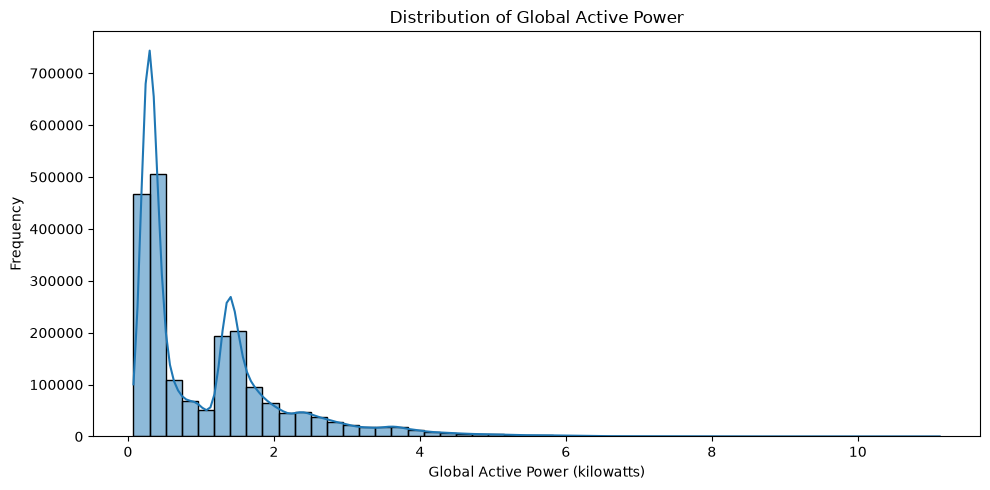

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Global_active_power",
    bins=50,
    kde=True
)

plt.title("Distribution of Global Active Power")
plt.xlabel("Global Active Power (kilowatts)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

This cell plots the distribution of global active power using a histogram and a kernel density estimate. It helps reveal common consumption levels, distribution asymmetry, and potentially high-consumption observations.

### Interpretation

The distribution of Global Active Power is positively skewed (right-skewed). Most observations correspond to relatively low electricity consumption, particularly below 1 kW. A second concentration appears around 1.4 kW, while high consumption values occur less frequently. The distribution has a long right tail, with a maximum value above 11 kW.

This distribution suggests that electricity consumption varies considerably over time and is not symmetrically distributed.

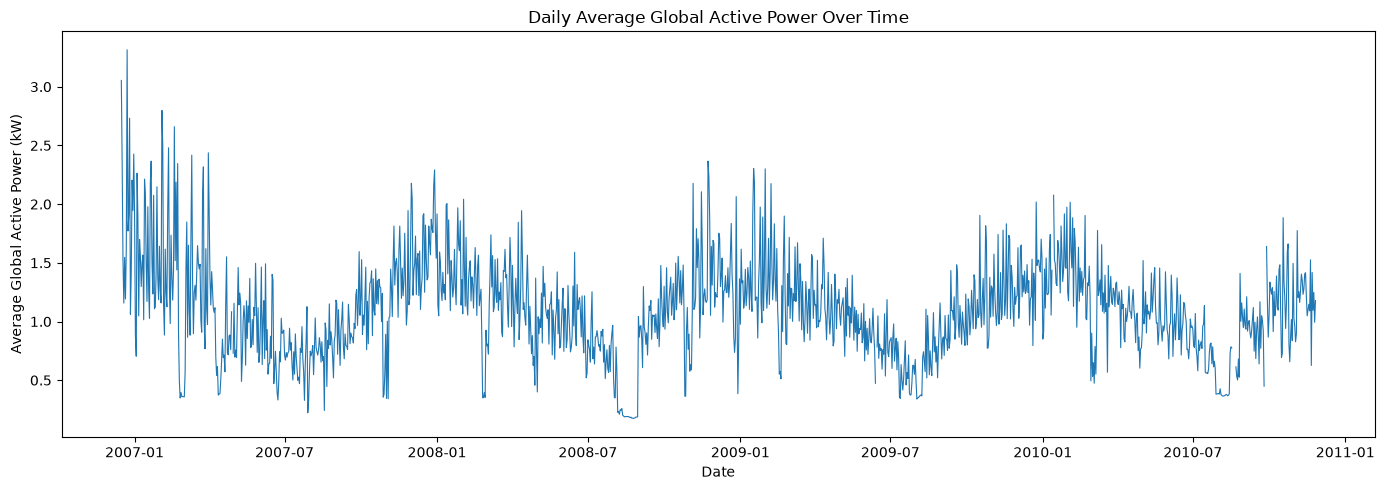

In [6]:
daily_power = df["Global_active_power"].resample("D").mean()

plt.figure(figsize=(14, 5))

plt.plot(daily_power, linewidth=0.8)

plt.title("Daily Average Global Active Power Over Time")
plt.xlabel("Date")
plt.ylabel("Average Global Active Power (kW)")
plt.tight_layout()
plt.show()

This cell calculates the daily average of Global Active Power and plots its evolution over time. Daily aggregation reduces visual clutter and helps reveal long-term trends, recurring patterns, and unusual periods.

### Interpretation

The daily average Global Active Power shows substantial fluctuations throughout the observation period. Recurring rises and falls suggest possible seasonal patterns, although further analysis is required to confirm them. Several periods exhibit unusually low daily averages, which should be interpreted cautiously because the dataset contains long gaps in the measurements. No clear long-term increasing or decreasing trend can be established from this plot alone.

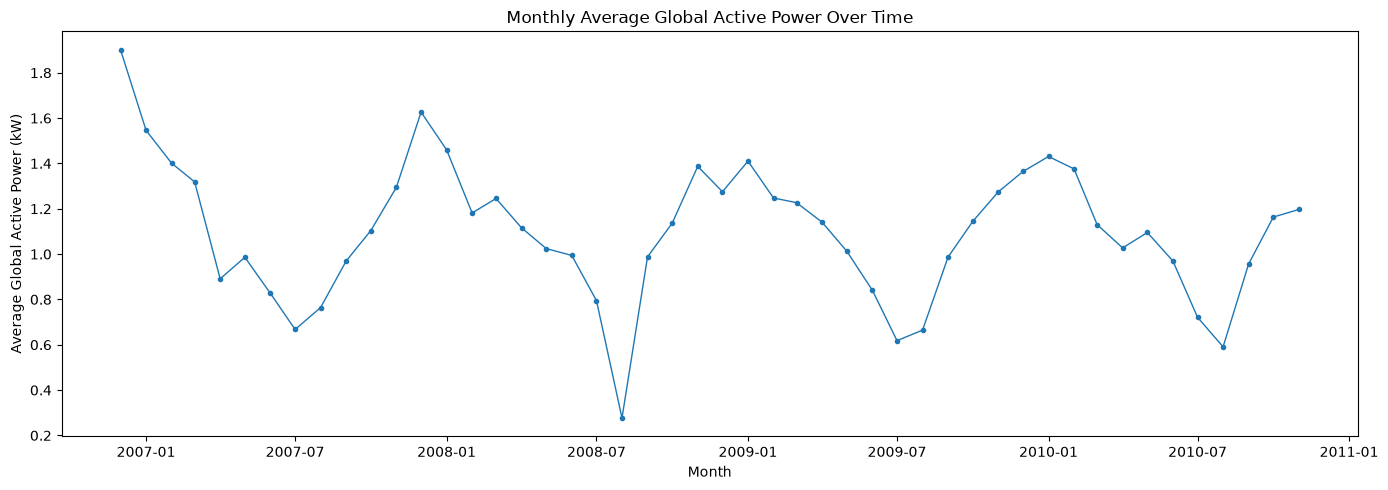

In [7]:
monthly_power = df["Global_active_power"].resample("MS").mean()

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_power.index,
    monthly_power.values,
    marker="o",
    markersize=3,
    linewidth=1
)

plt.title("Monthly Average Global Active Power Over Time")
plt.xlabel("Month")
plt.ylabel("Average Global Active Power (kW)")
plt.tight_layout()
plt.show()

This cell calculates the monthly average of Global Active Power and plots its evolution over time. Monthly aggregation smooths daily fluctuations and helps examine possible long-term and seasonal patterns.

### Interpretation

The monthly average Global Active Power exhibits recurring fluctuations, suggesting possible seasonal patterns. However, the sharp decrease in August 2008 may be influenced by missing measurements and should be investigated before drawing conclusions. The first month is also incomplete because the dataset begins in mid-December 2006. Overall, the plot does not show a clear, consistent long-term linear trend.

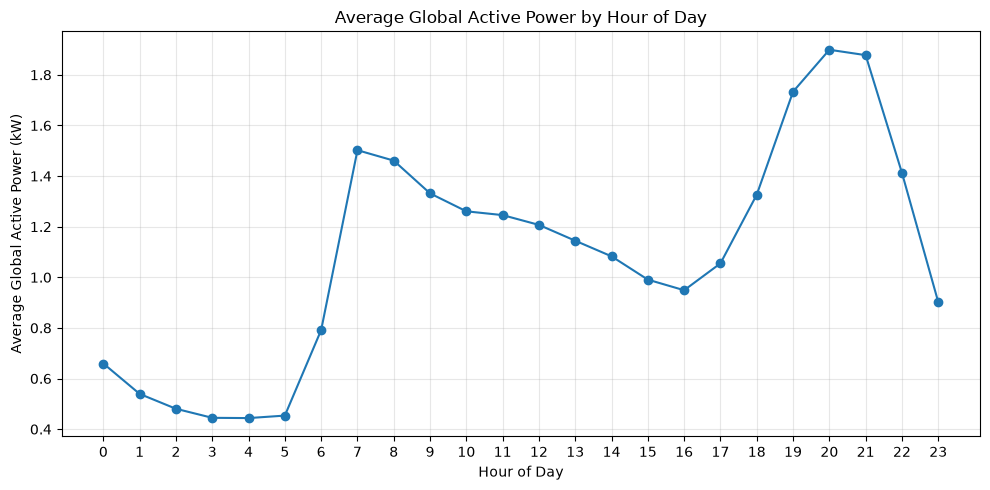

In [8]:
hourly_power = (
    df["Global_active_power"]
    .groupby(df.index.hour)
    .mean()
)

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_power.index,
    hourly_power.values,
    marker="o"
)

plt.title("Average Global Active Power by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Global Active Power (kW)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This cell groups electricity measurements by hour of the day and calculates the average Global Active Power for each hour. The plot helps identify daily consumption patterns and peak usage periods.

### Interpretation

The hourly average Global Active Power reveals a clear daily consumption pattern. Consumption is lowest during the early morning hours, increases sharply around 7:00 AM, and reaches its highest level around 8:00 PM. A gradual decrease occurs during much of the daytime, followed by a strong evening increase. These patterns suggest that the hour of the day may be a useful feature for electricity consumption prediction.


C:\Users\hp\AppData\Local\Temp\ipykernel_29000\3301862036.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  .groupby(df.index.dayofweek)


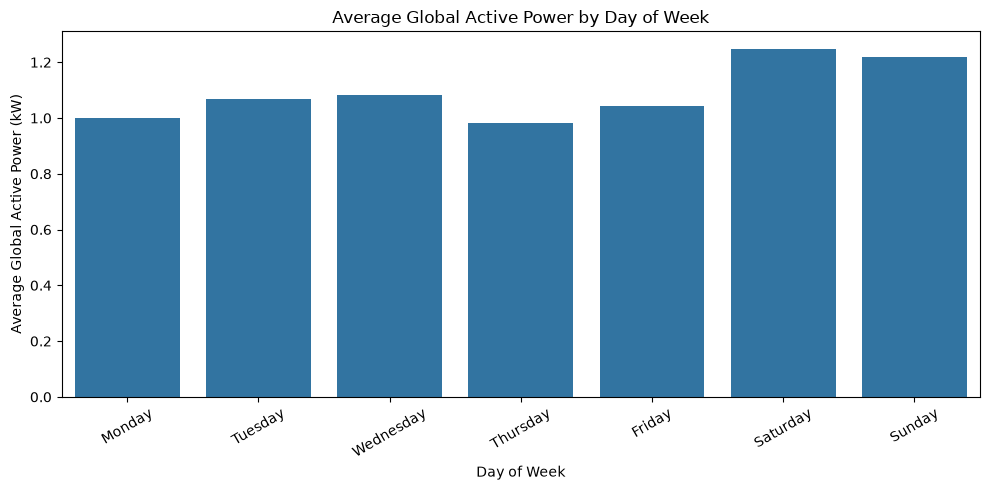

In [9]:
daily_power_by_weekday = (
    df["Global_active_power"]
    .groupby(df.index.dayofweek)
    .mean()
)

weekday_names = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

daily_power_by_weekday.index = weekday_names

plt.figure(figsize=(10, 5))

sns.barplot(
    x=daily_power_by_weekday.index,
    y=daily_power_by_weekday.values
)

plt.title("Average Global Active Power by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Global Active Power (kW)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

This cell calculates the average Global Active Power for each day of the week and displays the results in a bar chart. It helps compare weekday and weekend consumption patterns.

### Interpretation

The average Global Active Power varies across the days of the week. Saturday has the highest average consumption, followed by Sunday, while Thursday has the lowest. Weekend consumption appears higher than weekday consumption in this dataset. This suggests that the day of the week may be a useful feature for electricity consumption prediction, although the chart alone does not establish the cause of these differences.

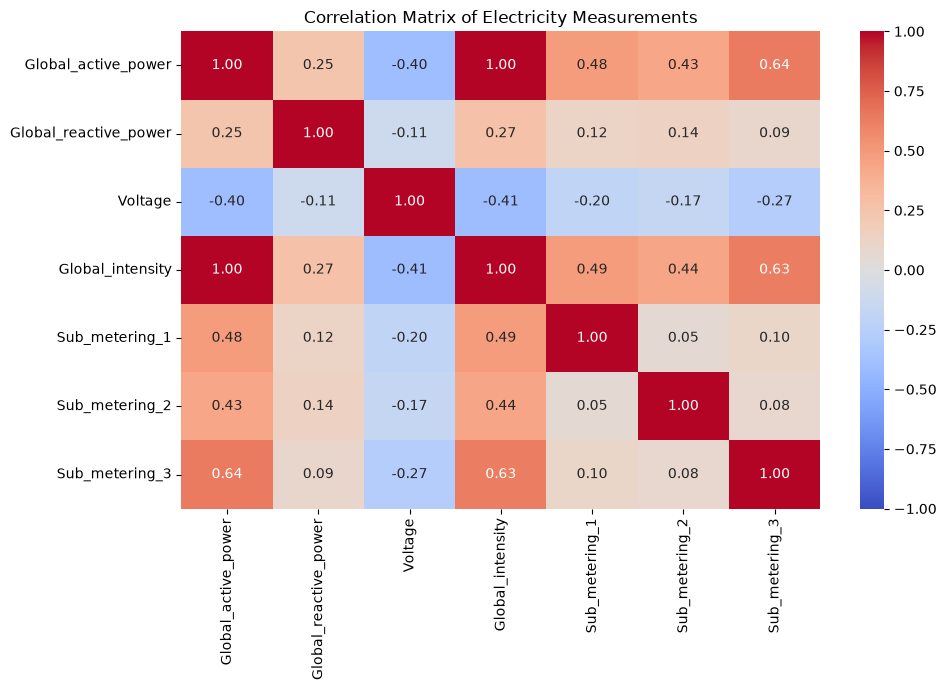

In [10]:
correlation_matrix = df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Electricity Measurements")
plt.tight_layout()
plt.show()

This cell calculates the pairwise correlations between numerical variables and visualizes them using a heatmap. Correlation coefficients range from -1 to 1, indicating negative, weak, or positive linear relationships.

### Interpretation

The correlation matrix shows a very strong positive correlation between Global Active Power and Global Intensity (1.00). Global Active Power is also positively correlated with Sub_metering_3 (0.64), Sub_metering_1 (0.48), and Sub_metering_2 (0.43). Voltage has a moderate negative correlation with Global Active Power (-0.40). Most correlations involving Global Reactive Power are relatively weak.

These results highlight relationships among electricity measurements. However, correlation does not imply causation, and highly correlated variables should be evaluated carefully when selecting features for predictive modeling.

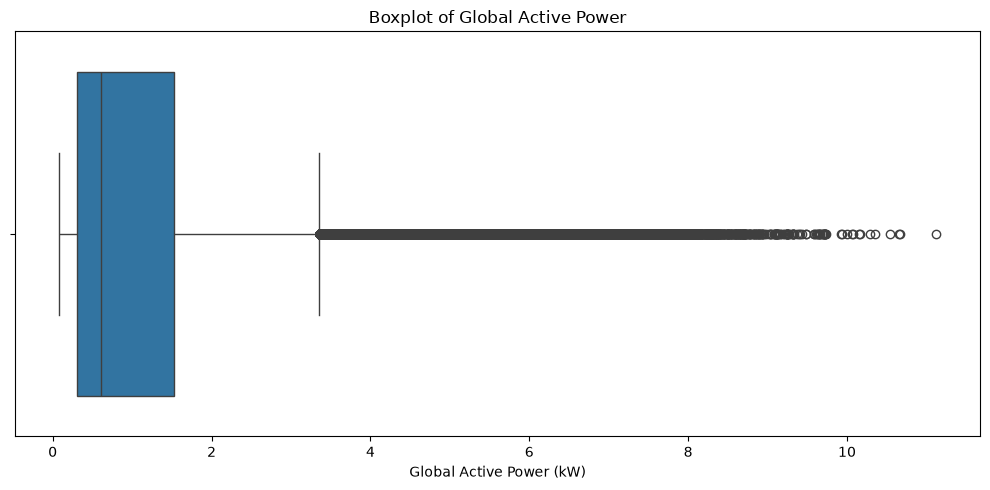

In [11]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["Global_active_power"].dropna()
)

plt.title("Boxplot of Global Active Power")
plt.xlabel("Global Active Power (kW)")
plt.tight_layout()
plt.show()

This cell creates a boxplot of Global Active Power to identify unusually high or low observations. Points beyond the whiskers are potential outliers and should be investigated rather than automatically removed.

### Interpretation

The boxplot reveals a strongly right-skewed distribution of Global Active Power, with many observations above the upper whisker. The median is approximately 0.60 kW, and the central 50% of observations lie roughly between 0.31 and 1.53 kW. Several high-consumption observations exceed 10 kW.

These points are potential outliers, but they may represent genuine periods of high electricity consumption. Therefore, they should not be removed automatically without further investigation.

In [12]:
power = df["Global_active_power"].dropna()

Q1 = power.quantile(0.25)
Q3 = power.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = power[
    (power < lower_bound) | (power > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of potential outliers:", len(outliers))
print("Percentage of potential outliers:", round(len(outliers) / len(power) * 100, 2), "%")

Q1: 0.308
Q3: 1.528
IQR: 1.22
Lower bound: -1.522
Upper bound: 3.358
Number of potential outliers: 94919
Percentage of potential outliers: 4.63 %


This cell applies the Interquartile Range (IQR) method to identify potential outliers in Global Active Power. It calculates the quartiles, IQR-based bounds, number of observations outside those bounds, and their percentage of non-missing measurements.

### Interpretation

The IQR method identifies 94,919 potential outliers in Global Active Power, representing 4.63% of non-missing observations. The upper threshold is 3.358 kW, while the lower threshold is negative and therefore does not identify any lower outliers in this non-negative consumption variable.

These observations may represent genuine high-consumption periods rather than data errors. They will be retained for further investigation instead of being removed automatically.

In [13]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})

display(missing_summary)

,Missing_Count,Missing_Percentage
Global_active_power,25903,1.25
Global_reactive_power,25903,1.25
Voltage,25903,1.25
Global_intensity,25903,1.25
Sub_metering_1,25903,1.25
Sub_metering_2,25903,1.25
Sub_metering_3,25903,1.25


This cell summarizes the remaining missing values for each measurement variable, reporting both the number and percentage of missing observations. This helps document data quality before the next stage of the project.

# Conclusion

The exploratory data analysis revealed several important characteristics of household electricity consumption:

- **Distribution:** Global Active Power is right-skewed, with most observations showing relatively low consumption and a smaller number of high-consumption values.
- **Temporal patterns:** Daily, monthly, and hourly averages show substantial fluctuations. Hourly analysis indicates lower consumption overnight and higher consumption in the morning and evening.
- **Weekly patterns:** Average consumption is higher on Saturday and Sunday than on most weekdays in this dataset.
- **Correlations:** Global Active Power is strongly positively correlated with Global Intensity (1.00) and moderately positively correlated with Sub_metering_3 (0.64).
- **Potential outliers:** The IQR method identified 94,919 potential outliers, representing 4.63% of non-missing Global Active Power observations. These values were retained because they may reflect genuine consumption peaks.
- **Missing data:** Each measurement variable retains 25,903 missing values (1.25%). These values occur in longer gaps that were not interpolated during the cleaning stage.

These findings will guide feature engineering and model selection. Further care is needed when handling missing periods and selecting predictors to prevent misleading results or data leakage.